# Übung Analysis

**Python kann bei vielen der Aufgaben unterstützend helfen.**

## Aufgabe 1

Fassen Sie folgende Summe zusammen und berechnen Sie den Wert (Überprüfe in Python).

$$\sum_{v=2}^{14} (v-1)^2 + \sum_{w=-2}^8 2\cdot(w+3) + \sum_{k=10}^{31} 1$$

### Lösung

$$\sum_{v=0}^{12} (v+1)^2 + \sum_{w=0}^{10} 2\cdot(w+1) + \sum_{k=0}^{21} 1$$

Nun können wir die Summen zusammenziehen, aber müssen auf die oberen Grenzen aufpassen (die kleinste ist $10$). Die Indexvariable können wir dazu einfach umbenennen. 

$$\sum_{i=0}^{10} ((i+1)^2 + 2\cdot (i+1) + 1) + \sum_{i=11}^{12} (i+1)^2 + \sum_{i=11}^{21} 1$$

Wir können die hinteren beiden Termine einfach ausrechnen.

$$\sum_{i=0}^{10} ((i+1)^2 + 2\cdot (i+1) + 1) + 144 + 169 + 11 = \sum_{i=0}^{10} ((i+1)^2 + 2\cdot (i+1) + 1) +324$$

Wir können nun sehr einfach in Python testen ob wir dies korrekt getan haben und wir können die Zeit messen. Die Zusammenfassung kann zudem schneller berechnet werden.

In [13]:
from time import time

n = 100000
start = time()
for j in range(n):
    summe = 0
    for v in range(2,15):
        summe += (v-1)**2
    for w in range(-2,9):
        summe += 2*(w+3)
    for k in range(10,32):
        summe += 1
print(f"Dauer {time()-start}s")
print(summe)

start = time()
for j in range(n):
    summe = 324
    for i in range(11):
        summe += ((i+1)**2 + 2*(i+1)+1)
print(f"Dauer {time()-start}s")
print(summe)

Dauer 0.16645574569702148s
973
Dauer 0.07684516906738281s
973


## Aufgabe 2

Bestimmen Sie die erste Ableitung der Funktion

$$f(x) = \frac{x^3+7}{cos(\frac{\pi x}{5})}$$
  
und testen Sie dies in Python mit Hilfe des Differentialquotient

$$f'(x) = \lim_{e\rightarrow 0}\frac{f(x+e)-f(x)}{e}$$

für verschiedene Werte.

### Lösung

Zuerst berechnen wir die Ableitung. Im ersten Schritt nutzen wir die Quotientenregel.
$$
f'(x) = \frac{3x^2\cdot cos\left(\frac{\pi x}{5}\right) - (x^3+7)\cdot \left(cos\left(\frac{\pi x}{5}\right)\right)'}{cos\left(\frac{\pi x}{5}\right)^2}
$$

Nun müssen wir den fehlenden Term $\left(cos\left(\frac{\pi x}{5}\right)\right)'$ mittels der Kettenregel ableiten. Hierzu benötigen wir, dass die Ableitung von $cos$ gleich $-sin$ ist.

$$
f'(x) = \frac{3x^2\cdot cos\left(\frac{\pi x}{5}\right) - (x^3+7)\cdot \left(-sin\left(\frac{\pi x}{5}\right)\cdot \frac{\pi}{5}\right)}{cos\left(\frac{\pi x}{5}\right)^2}
$$

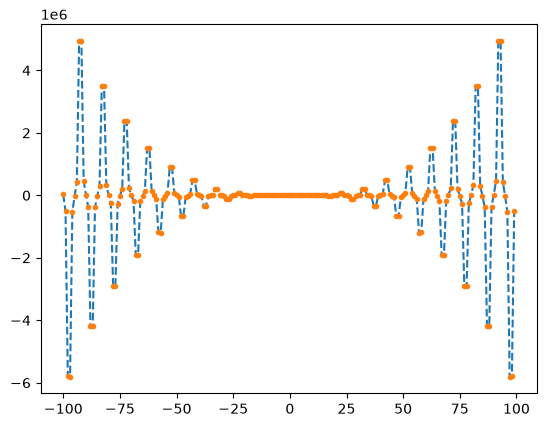

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Funktionsdefinition
def f(x):
    return (x**3+7)/np.cos((np.pi * x)/5)

# Ableitung
def g(x):
    return ((3*x**2+7)*np.cos((np.pi * x)/5)+(x**3+7)*np.sin((np.pi * x)/5)*(np.pi)/5)/np.cos((np.pi * x)/5)**2

# Differentialquotient
def dq(x,e=1e-8):
    return (f(x+e)-f(x))/e
    
# Lets plot it on a scale from -100 to 100
plt.plot(np.arange(-100,100), [g(x) for x in np.arange(-100,100)], "--")
plt.plot(np.arange(-100,100), [dq(x) for x in np.arange(-100,100)], ".")
plt.show()

## Aufgabe 3

Sei 

$$f(x) = x^2 + 4+x^3$$

berechnen Sie numerisch die Fläche auf dem Intervall $[-2,0]$ mithife von Python.

4.0
6.460000000000001
6.6466
6.668665999999831
6.666866659999836
6.666646666609472


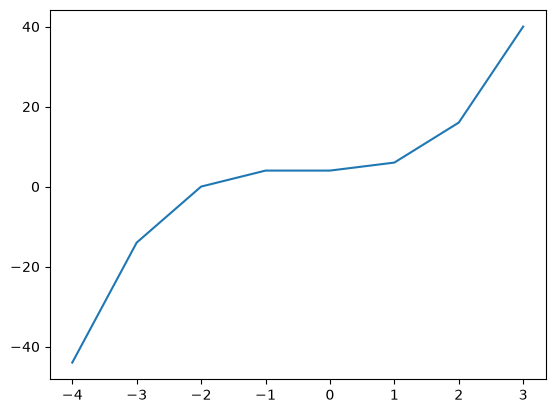

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return x**2 + 4 + x**3
    
interval = 4
plt.plot(np.arange(-interval,interval), [f(i) for i in np.arange(-interval, interval)])

# check with different epsilons
for eps in range(6):
    eps = 1/10**eps
    area = 0.0
    # area under x=-2
    x = -2
    # to zero
    while x < 0:
        area += f(x)*eps
        x += eps
    print(area)